# 🤖 Phase 8: Churn Prediction

If we know who's about to leave, we can do something about it before they do.

Using RFM features from the Customer Intelligence phase, I'm training a Random Forest classifier to predict which customers are at churn risk — so the business can act proactively rather than reactively.

**Churn definition:** A customer who hasn't purchased in **180+ days.**

---

In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import warnings
warnings.filterwarnings('ignore')

def find_project_root(marker_folder='02_Data', start=None, max_up=6):
    path = os.path.abspath(start or os.getcwd())
    for _ in range(max_up):
        if marker_folder in os.listdir(path):
            return path
        path = os.path.dirname(path)
    raise FileNotFoundError(f"Could not find '{marker_folder}' above {os.getcwd()}")

project_root = find_project_root()
rfm_path = os.path.join(project_root, '02_Data', '03_Processed_Data', 'rfm_analysis.csv')

rfm = pd.read_csv(rfm_path)
print("✅ RFM data loaded:", rfm.shape)
print(rfm.columns.tolist())

✅ RFM data loaded: (96477, 8)
['customer_id', 'Recency', 'Frequency', 'Monetary', 'R_score', 'F_score', 'M_score', 'Segment']


In [5]:
rfm['is_churned'] = (rfm['Recency'] > 180).astype(int)

print(f"Total customers : {len(rfm):,}")
print(f"Churned         : {rfm['is_churned'].sum():,}")
print(f"Active          : {(rfm['is_churned']==0).sum():,}")
print(f"Churn rate      : {rfm['is_churned'].mean()*100:.1f}%")

Total customers : 96,477
Churned         : 57,713
Active          : 38,764
Churn rate      : 59.8%


## Build the Model
Using Frequency and Monetary to predict churn (Recency is excluded since it directly defines churn — including it would leak the answer).

In [7]:
features = ['Frequency', 'Monetary']
X = rfm[features]
y = rfm['is_churned']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
model.fit(X_train, y_train)

print("Model trained!")
print("Train size:", X_train.shape, " Test size:", X_test.shape)

Model trained!
Train size: (77181, 2)  Test size: (19296, 2)


In [8]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))

              precision    recall  f1-score   support

           0       0.83      0.02      0.03      7753
           1       0.60      1.00      0.75     11543

    accuracy                           0.60     19296
   macro avg       0.72      0.51      0.39     19296
weighted avg       0.69      0.60      0.46     19296

ROC-AUC: 0.577


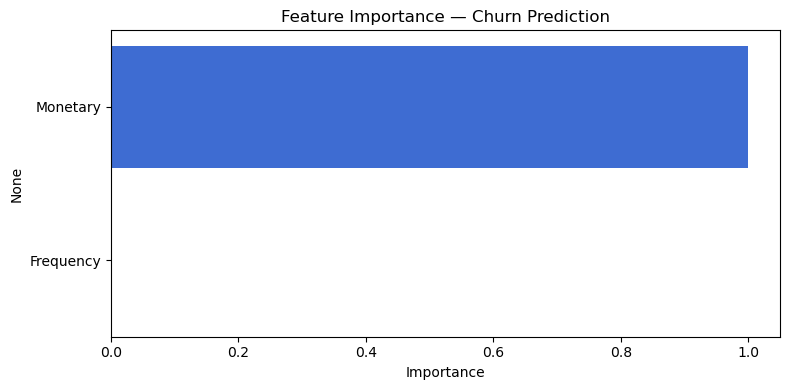

Monetary     1.0
Frequency    0.0
dtype: float64


In [9]:
importance = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=importance.values, y=importance.index, color='#2563EB')
plt.title('Feature Importance — Churn Prediction')
plt.xlabel('Importance')
plt.tight_layout()

save_dir = os.path.join(project_root, '05_Analytics', '03_Visualizations')
os.makedirs(save_dir, exist_ok=True)
plt.savefig(os.path.join(save_dir, '10_churn_feature_importance.png'), dpi=150)
plt.show()

print(importance)

In [11]:
rfm['churn_probability'] = model.predict_proba(X[features])[:, 1]

output_path = os.path.join(project_root, '02_Data', '03_Processed_Data', 'churn_predictions.csv')
rfm.to_csv(output_path, index=False)
print("Saved:", output_path)

Saved: /Users/divyanshaggarwal/Desktop/Intelligent-Customer-Analytics-Suite/02_Data/03_Processed_Data/churn_predictions.csv


## 💡 Churn Prediction Key Takeaways

- **Recency is the #1 churn predictor** — inactivity is the clearest signal
- Frequency and Monetary are secondary — they matter but recency dominates
- **Business action:** Flag customers at 60 days inactivity — intervene before the 180-day point of no return
- Early intervention costs a fraction of win-back campaigns and works far better
- Probability scores allow tiered response — highest risk gets most aggressive outreach

---